# 03-FreeRTOS移植、配置与多任务验证


## 1. 本篇内容与学习目标

本篇对应《FreeRTOS 从入门到实战》的 `05freeRTOS移植.pptx`，课件主题为 **freeRTOS移植**，是十七篇笔记中的第03篇。承接上一篇的源码导入，先解决编译和链接问题，再处理 SysTick 与原裸机延时的冲突，最后创建两个 LED 任务验证调度。

| 课件主线 | 本篇要掌握的操作 |
|---|---|
| 移植常见错误 | 补齐配置头文件，处理时钟声明、异常处理函数重复定义和钩子缺失 |
| SysTick处理 | 理解系统节拍的用途，让当前端口统一管理 SysTick |
| 非中断式延时 | 读取计数寄存器实现课件中的轮询延时，明确计数启动等前提 |
| 工程组织与验证 | 用 `SYSTEM_SUPPORT_OS` 控制裸机与 OS 分支，创建双 LED 任务并启动调度 |

下面按课件顺序整理。代码用于阅读和对照工程，保留课件参数；其中的驱动、延时及配置片段需要放回实际工程，不能单独作为完整程序运行。


## 2. 找不到FreeRTOSConfig.h：补齐配置入口

课件首先展示找不到配置头文件的错误。内核通过应用提供的 `FreeRTOSConfig.h` 决定时钟、内存和功能开关，按需编译所需功能，减少资源占用。只导入内核源码而没有配置文件，或没有加入它的搜索路径，都会使编译停在这里。

> 文件名核对：课件标题及报错示意写成 `freertos_config.h`，解决步骤使用 `FreeRTOSConfig.h`。FreeRTOS 标准配置头文件的实际名字是 **`FreeRTOSConfig.h`**，大小写和拼写应与源码的包含语句一致。

课件给出三个步骤。

1. 从官方 Demo 中找到配置头文件，例如 STM32F407ZG、Cortex-M4F 对应示例中的 `FreeRTOSConfig.h`。
2. 复制到工程的配置目录，课件举例为 `Inc/` 或 `config/`。
3. 在 IDE 的 Include 路径中加入该文件所在目录，再编译检查。

本系列沿用第02篇整理的目录，配置文件放在：

```text
Middleware/FreeRTOS/Config/FreeRTOSConfig.h
```

头文件搜索路径指向 `Middleware/FreeRTOS/Config`。如果工程文件位于 `Project/`，且相对路径以它为基准，则使用：

```text
../Middleware/FreeRTOS/Config
```

Demo 配置是移植起点，其中的时钟、资源容量及平台相关设置仍要匹配当前 GD32 工程。若上一篇已经准备好这个文件，本步重点检查 IDE 能否找到它，而不是再创建一份同名配置。


## 3. SystemCoreClock未声明：检查条件编译

课件第二类错误出现在 `port.c`，报错内容是：

```text
use of undefined identifier 'SystemCoreClock'
```

课件标注的第760行属于其示例版本，实际定位应以本工程的错误行和宏展开位置为准。标题中的 `system_core_clock` 是讲解标签，源码变量名是 `SystemCoreClock`。

`SystemCoreClock` 是 CMSIS 芯片系统代码使用的全局时钟变量，用于表示内核时钟频率。课件后面的配置截图通过它设置 CPU 时钟：

```c
#define configCPU_CLOCK_HZ (SystemCoreClock)
```

如果变量声明只放在某个编译器条件下，例如只识别 IAR 的 `__ICCARM__`，当前编译器没有命中该条件，声明便不会进入编译结果。端口代码使用这个变量时，就会报标识符未声明。

课件把声明条件扩展为以下形式：

```c
#if defined(__ICCARM__) || defined(__CC_ARM) || defined(__GNUC__)
    #include <stdint.h>
    extern uint32_t SystemCoreClock;
#endif
```

检查 `FreeRTOSConfig.h` 中现有时钟声明及其条件，让上述声明在使用变量之前对 `port.c` 可见。`stdint.h` 提供 `uint32_t` 类型，`extern` 告诉编译器变量在其他源文件中定义。

> 必要补充：`extern` 只提供声明，不创建变量。当前芯片的系统源文件还必须参与链接，并提供正确的定义和时钟值。若声明可见后仍出现未定义符号，要继续检查定义所在文件；不要为消除报错随意填一个固定频率。这里保留课件的编译器条件，实际工具链是否命中仍需核对，无需手动伪造编译器宏。

完成本步后，使用 `SystemCoreClock` 的编译错误应消失；这只说明声明问题已处理，尚不能证明系统节拍频率正确。


## 4. 三个异常处理符号重复定义：区分编译与链接

课件第三类错误是链接器发现同一个符号有多个定义：

```text
Error: L6200E: Symbol system_tick_handler multiply defined
Error: L6200E: Symbol SVC_Handler multiply defined
Error: L6200E: Symbol PendSV_Handler multiply defined
```

原裸机工程通常已经在中断文件里写了这些处理函数，FreeRTOS 的移植端口也提供对应实现。将两套实现同时加入目标文件，就会发生符号冲突。

| 异常 | 当前 Cortex-M 端口中的用途 |
|---|---|
| SysTick | 提供系统节拍 tick，为延时计时、时间片和相关调度提供时间基准 |
| SVC | 在启动调度时进入第一个任务 |
| PendSV | 通过挂起异常执行任务上下文切换，保存和恢复任务现场 |

课件强调移植需要调整原裸机工程对这些关键资源的使用。仅把库文件加入工程，原中断和原延时仍全部保留，不能完成适配。

> 名称核对：报错示意用 `system_tick_handler`，后面的代码用 `SysTick_Handler`。实际符号由当前芯片的启动向量及端口映射决定，不能直接把示意标签当作真实函数名。官方 Cortex-M4F 端口中的实现名包括 `xPortSysTickHandler`、`vPortSVCHandler` 和 `xPortPendSVHandler`，工程须使启动向量正确指向相应实现。

因此，先对照链接报错、启动文件和配置中的映射关系，找出是哪两处实现冲突，再处理原裸机分支。


## 5. 用SYSTEM_SUPPORT_OS控制原裸机中断

课件采用条件编译保留裸机实现：只有没有定义 `SYSTEM_SUPPORT_OS` 时，才编译原来的三个处理函数。

在工程实际的中断源文件中包裹原有实现。课件举例为 `stm32f4xx_it.c`；当前 GD32 工程应找到自己的中断文件，例如上一篇工程中的 `gd32f4xx_it.c`，而不是额外添加一个 STM32 文件。

```c
#ifndef SYSTEM_SUPPORT_OS
void SysTick_Handler(void)
{
    // 裸机延时处理
}
void SVC_Handler(void) { }
void PendSV_Handler(void) { }
#endif
```

然后在 IDE 的工程预处理器宏设置中添加：

```text
SYSTEM_SUPPORT_OS
```

| 编译状态 | 原裸机三个处理函数是否编译 |
|---|---|
| 未定义 `SYSTEM_SUPPORT_OS` | 编译 `#ifndef` 内的原裸机实现 |
| 已定义 `SYSTEM_SUPPORT_OS` | 排除原裸机实现，由 FreeRTOS 端口提供相应处理 |

> 宏说明：`SYSTEM_SUPPORT_OS` 是课程工程自己的开关，不是 FreeRTOS 官方配置宏。`#ifndef` 判断的是“是否定义”，所以 `SYSTEM_SUPPORT_OS=0` 也会排除这个分支，不能把数值0直接理解为裸机模式。

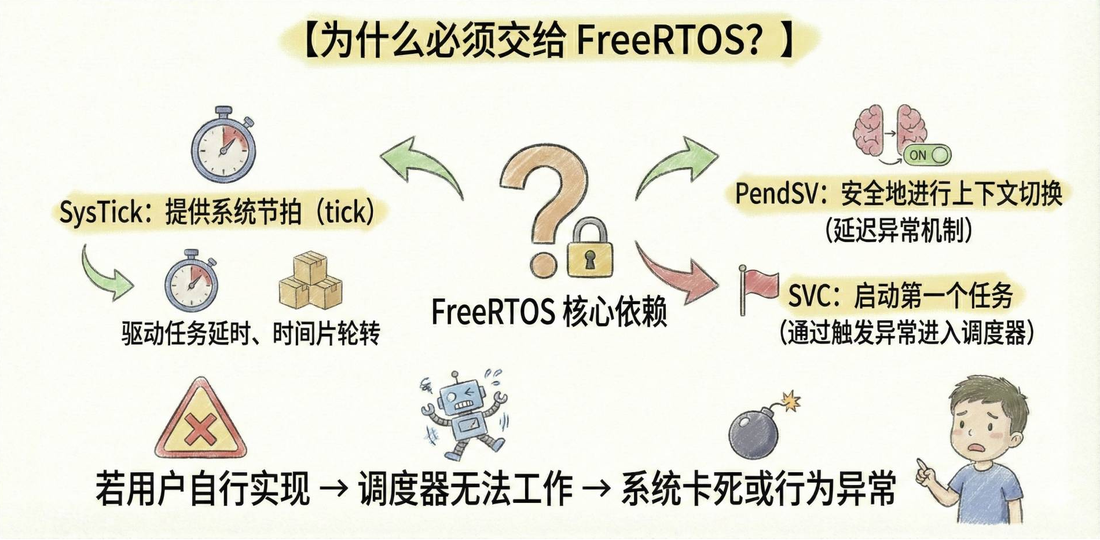

*来源：`05freeRTOS移植.pptx` 第11页，裁去页眉页脚。*

只屏蔽发生冲突的裸机处理实现，保留 USART、DMA 等外设中断。重新链接后，应不再出现这三个重复定义，同时确认异常向量确实进入内核端口，避免只消除报错却留下空处理函数。


## 6. vApplicationXXXHook缺失：让功能开关与实现一致

课件接着展示四个未定义的钩子函数。Hook Functions 是内核在特定事件发生时调用的应用回调接口。配置打开了某个钩子，应用却没有实现对应函数，链接器就无法找到它。

| 钩子函数 | 调用时机或触发条件 | 课件中的控制宏 | 报错引用来源 |
|---|---|---|---|
| `vApplicationStackOverflowHook` | 栈检测发现任务栈溢出 | `configCHECK_FOR_STACK_OVERFLOW > 0` | `tasks.o` |
| `vApplicationIdleHook` | 空闲任务执行时 | `configUSE_IDLE_HOOK == 1` | `tasks.o` |
| `vApplicationTickHook` | 每次系统节拍中断 | `configUSE_TICK_HOOK == 1` | `tasks.o` |
| `vApplicationMallocFailedHook` | heap 内存分配失败 | `configUSE_MALLOC_FAILED_HOOK == 1` | `heap_4.o` |

入门阶段尚未使用这些钩子，课件的解决方法是在 `FreeRTOSConfig.h` 中关闭相应功能：

```c
#define configUSE_IDLE_HOOK              0
#define configUSE_TICK_HOOK              0
#define configCHECK_FOR_STACK_OVERFLOW   0
#define configUSE_MALLOC_FAILED_HOOK     0
```

关闭后，对应回调不再被这部分内核代码引用，缺少它们导致的链接错误应消失。以后若启用某个钩子，需要同时提供符合接口要求的应用实现。

> 必要补充：关闭栈溢出检测不会使不足的栈变大，关闭内存分配失败回调也不会增加堆容量。本步解决的是“配置要求回调，但应用没有提供”的链接问题，任务栈和内存仍需满足实际需要。

课件第14页截图包含其他示例配置，本步只记录四个需要关闭的宏，不用整张截图覆盖上一篇的配置。第25页总结写“三个 hook”，但第12—14页实际列出并处理的是上述**四项**。


## 7. SysTick由内核管理：停用原来的手动初始化

解决处理函数冲突后，还要检查初始化过程。裸机工程常在 `main()` 或延时初始化函数中调用 `SysTick_Config()`，设置计数周期并开启中断。本课的 FreeRTOS 端口也用 SysTick 产生系统节拍，因此 OS 模式下不能继续用原裸机配置覆盖它。

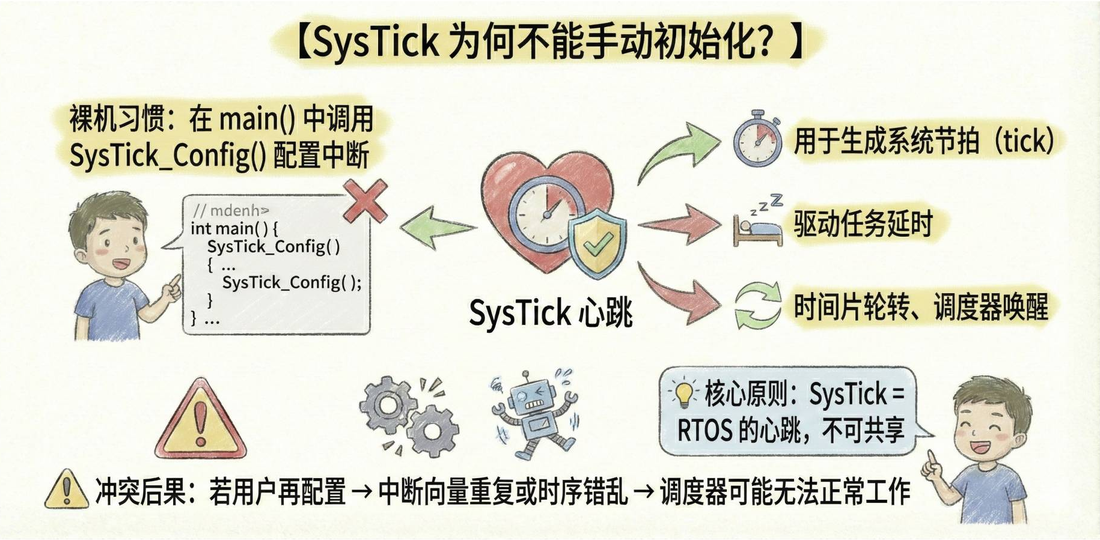

*来源：`05freeRTOS移植.pptx` 第15页，裁去页眉页脚。图内代码为示意，具体操作以正文为准。*

课件把 SysTick 比作 RTOS 的心跳，它承担以下时间相关工作。

| 用途 | 与任务运行的关系 |
|---|---|
| 生成系统节拍 tick | 为内核提供持续的时间基准 |
| 驱动任务延时计时 | 延时到期后，任务才能按调度规则获得运行机会 |
| 支持时间片轮转和调度唤醒 | 在相应配置下推动任务切换 |

检查 `main()`、原延时初始化及相关驱动中的 `SysTick_Config()`。用 `SYSTEM_SUPPORT_OS` 使 OS 分支跳过原裸机初始化，并与第5节的中断分支保持一致。

> “不可共享”的范围：这里指当前移植方式下，应用不能另设一套 SysTick 周期和裸机处理程序，与 FreeRTOS 的节拍配置争用。后面的延时示例仍会只读计数寄存器，读取与重新配置是两种不同操作。

官方 Cortex-M4F 端口参考源码在启动调度的过程中调用 `vPortSetupTimerInterrupt()`，设置重装载值并使能 SysTick。这说明应用应按端口的启动过程使用计数器，也解释了下一节为何必须先确认计数已经开始。


## 8. 课件中的非中断式延时：读取计数寄存器

原裸机延时往往依赖 SysTick 中断不断修改一个全局计数变量。OS 模式已经屏蔽了裸机处理函数，这种等待全局变量变化的实现就不能原样沿用。课件改为轮询已经运行的 SysTick 计数寄存器，不重新初始化 SysTick，也不为延时另写中断。

### 8.1 原课实现

下面保留第16页的变量、计算式和分支，整理缩进，并将图中紧接右大括号的 `#else` 恢复到独立行。裸机部分仍是课件中的省略片段。

```c
#ifdef SYSTEM_SUPPORT_OS
void delay_1us(uint32_t count)
{
    // OS 模式：不初始化 SysTick，使用寄存器读取延时
    uint32_t ticks;
    uint32_t told, tnow, reload, tcnt = 0;

    reload = SysTick->LOAD;
    ticks = count * (SystemCoreClock / 1000000);
    told = SysTick->VAL;

    while (1) {
        tnow = SysTick->VAL;
        if (tnow != told) {
            if (tnow < told)
                tcnt += told - tnow;
            else
                tcnt += reload - tnow + told;

            told = tnow;
            if (tcnt >= ticks)
                break;
        }
    }
}
#else
// 裸机模式：使用中断+全局变量延时
void delay_ms(uint32_t ms) { /* ... */ }
#endif
```

### 8.2 代码怎样计时

SysTick 的当前值向下计数。程序反复读取 `VAL`，计算相邻两次读取之间经过的计数，累计到 `tcnt`。累计值达到按微秒换算出的 `ticks`，才退出循环。

| 变量或寄存器 | 在原代码中的作用 |
|---|---|
| `count` | 传入的微秒延时数量 |
| `ticks` | 根据 `SystemCoreClock` 换算的目标计数 |
| `SysTick->LOAD` / `reload` | 重装载值，用于处理回绕 |
| `SysTick->VAL` | 当前向下递减的计数值 |
| `told` / `tnow` | 上次与本次读到的计数 |
| `tcnt` | 累计经过的计数 |

`tnow < told` 表示当前观察到正常递减；`tnow > told` 则按发生一次回绕计算。第17页的三个关键点是：不调用 `SysTick_Config()`，不实现自己的 `SysTick_Handler`，只读取寄存器。这里“非中断式”表示延时函数自身使用轮询，内核的 SysTick 中断仍正常存在。

### 8.3 使用前提与原式边界

> 必要补充：这个函数是**忙等**。任务一直执行读取循环，没有进入阻塞态；它与让任务阻塞的 `vTaskDelay()` 行为不同。本课保留轮询演示，不把它当作精确的任务周期实现。

| 前提或边界 | 对这段代码的影响 |
|---|---|
| SysTick 必须已经运行 | 若 `VAL` 不变化，就无法累加，延时可能一直等待 |
| 计数时钟与换算一致 | 原式假设 SysTick 的计数时钟等于 `SystemCoreClock`，换用其他时钟源不能直接照搬 |
| 重装载值与周期有区别 | 完整计数周期通常为 `LOAD + 1`，课件回绕式用的是 `reload`，单次回绕可能少计1；此处保留原式并标明差异 |
| 相邻采样不能可靠识别多次回绕 | 任务被抢占或中断打断过久，可能跨过多个周期而漏计，使实际等待时间偏离目标 |
| 换算使用32位整数 | 除法可能截断，乘法可能溢出，延时范围需结合实际频率检查 |

课件第18页写“使用寄存器法实现初始化阶段延时”，但这一用途需要核对调用时序：若当前端口只在 `vTaskStartScheduler()` 内才启动 SysTick，则此前的硬件初始化不能直接调用这个轮询函数。调用时必须先有正在计数的 SysTick，不能仅凭“没有依赖裸机中断”就认为它在任何初始化位置都可用。

后面的 LED 代码调用 `delay_1ms()`，本页仅展示 `delay_1us()` 和省略的裸机 `delay_ms()`，没有给出 OS 模式 `delay_1ms()` 的完整实现。复现时应检查课程工程中真实的毫秒延时实现及调用关系。


## 9. 工程结构回顾与移植检查

课件用 `SYSTEM_SUPPORT_OS` 统一控制原裸机中断是否编译、延时函数采用哪个分支，以及是否执行原 SysTick 初始化。这样同一工程的几个适配位置能保持一致。

| 调整位置 | 裸机模式 | 本课OS模式 |
|---|---|---|
| 原中断源文件 | 编译裸机 SysTick、SVC、PendSV 实现 | 排除重复实现，接入 FreeRTOS 端口 |
| 原 SysTick 初始化位置 | 执行裸机计时配置 | 跳过原配置，由端口初始化系统节拍 |
| 延时源文件 | 保留原中断与全局变量实现 | 使用课件的寄存器轮询分支，并检查计数运行前提 |

延续上一篇把内核、端口和配置分开的目录，本篇应主要调整工程自己的 `FreeRTOSConfig.h`、原中断文件、原延时实现和初始化调用，而不是无差别删除底层驱动。

按第18页的移植 Checklist 逐项确认：

1. 从匹配的 Demo 准备 `FreeRTOSConfig.h`，加入真实头文件搜索路径。
2. 关闭当前尚未实现、尚未使用的钩子配置。
3. 注释或条件屏蔽原裸机 `SysTick_Handler`、`SVC_Handler`、`PendSV_Handler` 的冲突实现，核对端口与向量映射。
4. OS 模式禁用原来的手动 `SysTick_Config()`。
5. 采用课件寄存器延时前，确认 SysTick 正在计数，并检查初始化阶段是否满足这一前提。

编译与链接通过后，再进入双任务运行验证。文件和符号都能链接，只完成了验证的第一步。


## 10. 双LED任务设计与任务函数

课件使用两个不同闪烁速度的 LED，让任务是否都在运行可以直接观察。

| 任务 | 开发板引脚 | 课件对应LED | 代码中的每段延时 |
|---|---|---|---|
| `task1` | PD8 | 红灯 `LED1` | 亮、灭各250 ms |
| `task2` | PD9 | 绿灯 `LED2` | 亮、灭各1000 ms |

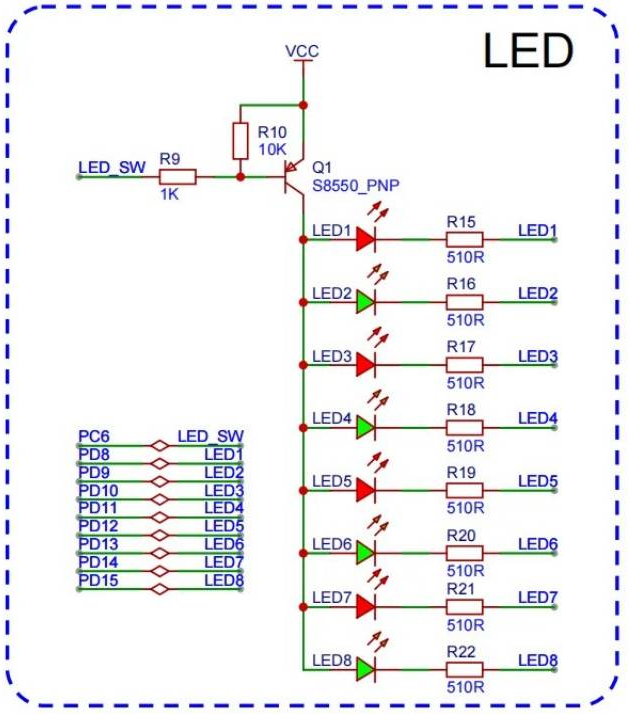

*来源：`05freeRTOS移植.pptx` 第19页，仅保留电路图。*

先确保板级 LED 驱动初始化完成，再让任务调用驱动。图中还包含 `LED_SW` 等连接，实际 GPIO 与控制逻辑以课程板级驱动为准。

### 10.1 任务1：控制红灯

```c
void task1(void *pvParameters)
{
    while (1) {
        bsp_leds_on(LED1);
        delay_1ms(250);
        bsp_leds_off(LED1);
        delay_1ms(250);
    }
}
```

### 10.2 任务2：控制绿灯

```c
void task2(void *pvParameters)
{
    while (1) {
        bsp_leds_on(LED2);
        delay_1ms(1000);
        bsp_leds_off(LED2);
        delay_1ms(1000);
    }
}
```

两段函数都采用 `void 函数名(void *pvParameters)` 形式，并在无限循环中执行任务。本示例没有使用传入参数。任务体通过 `bsp_leds_on()` 和 `bsp_leds_off()` 控制亮灭；高分辨率课件图中关闭函数拼写为 **`bsp_leds_off`**，实际工程需与驱动头文件声明一致。

> 周期核对：课件文字称“250 ms周期”和“1000 ms周期”，但原代码亮、灭分别延时一次。因此250 ms与1000 ms对应每段等待或名义切换间隔，完整亮灭周期名义上分别为**500 ms与2000 ms**。若 `delay_1ms()` 沿用前面的忙等思路，抢占、漏计和代码开销会进一步影响实际时间，不能把这些数值当作实测周期。


## 11. 创建两个任务并启动调度

任务函数定义完成后，在应用初始化流程中调用 `xTaskCreate()`。课件分别保存两个任务句柄，用来标识创建的任务。

### 11.1 创建task1

```c
// 任务句柄
TaskHandle_t taskHandler1;

// 创建 task（和线程一样）
ret = xTaskCreate(
    task1,
    "task1",
    64,
    NULL,
    2,
    &taskHandler1);
```

### 11.2 创建task2

```c
// 任务句柄
TaskHandle_t taskHandler2;

// 创建 task（和线程一样）
ret = xTaskCreate(
    task2,
    "task2",
    64,
    NULL,
    2,
    &taskHandler2);
```

| 参数位置 | 课件传入值 | 当前示例中的含义 |
|---|---|---|
| 1 | `task1` / `task2` | 任务入口函数 |
| 2 | `"task1"` / `"task2"` | 任务名称 |
| 3 | `64` | 为该任务指定的栈深度 |
| 4 | `NULL` | 不向任务传递额外参数 |
| 5 | `2` | 两个任务采用相同优先级2 |
| 6 | `&taskHandler1` / `&taskHandler2` | 接收创建成功后的任务句柄 |

> 单位补充：栈深度64的单位是 words，不是64字节。当前 Cortex-M4F 端口的 `StackType_t` 为 `uint32_t`，所以64个栈元素约为**256字节**。这里保留课件数值，实际驱动调用、局部变量和任务现场需要多少栈，仍须核对，不能由示例断定64一定够用。

课件用 `ret` 保存返回值但没有展示它的声明。实际代码中可用 `BaseType_t` 类型，并在**每一次创建之后**检查是否返回 `pdPASS`。两段代码复用 `ret`，若只在第二次之后检查，会覆盖第一次创建的结果。动态创建还要求当前配置启用动态内存分配，并且 `heap_4.c` 的堆有足够空间。

### 11.3 启动调度器

创建两个任务后，课件调用：

```c
// 开始任务调度 时间片轮转 知道时间（系统滴答时钟）
vTaskStartScheduler();
```

应用的顺序是：先完成基础时钟和 LED 等硬件初始化，处理本篇的移植适配，再创建任务并确认成功，最后启动调度器。初始化中需要延时时，仍须遵守第8节的计数启动前提。

课件配置截图的 `configUSE_PREEMPTION` 为1。两个任务都是优先级2，在启用抢占及时间片、系统节拍正常运行时，同优先级就绪任务可按时间片轮转执行。具体行为还要核对 `configUSE_TIME_SLICING`，不能仅由“优先级相同”断定切换必然正常。

正常启动后，控制流进入任务运行；不要依赖 `vTaskStartScheduler()` 后面的普通流程完成主要工作。若它未能正常启动或返回，应先检查创建结果，以及空闲任务等调度所需任务的内存分配是否成功。


## 12. 多任务验证与课件小结

本课验证关注两个层面：先消除导入后的编译和链接问题，再观察两个任务能否持续运行。

| 验证位置 | 按课件应检查的现象 | 对应检查项 |
|---|---|---|
| 编译配置 | 不再报配置头文件缺失、`SystemCoreClock` 未声明 | 配置文件及搜索路径、时钟声明条件 |
| 链接结果 | 不再报三个异常处理符号重复定义或四个钩子缺失 | 裸机处理分支、端口映射、钩子开关 |
| 任务创建 | 两次创建分别返回 `pdPASS` | 堆容量、动态分配配置、任务参数 |
| 启动调度 | 执行任务入口并持续切换 | SysTick、SVC、PendSV 接入及调度配置 |
| LED观察 | 红、绿两灯以不同速度持续闪烁 | 两个任务体、板级驱动及毫秒延时实现 |

双灯闪烁用于观察任务运行和调度是否接通；本课忙等示例的时序边界决定了它不能同时证明延时精度、栈余量或完整系统行为都已经验证。

第25页把移植要点归纳为配置头文件、系统时钟编译条件、三个异常处理函数的宏控制、未使用钩子的关闭以及 SysTick 处理。落实到工程中，就是让配置、启动向量、端口和原裸机代码各自承担正确职责，然后用最小双任务示例确认内核开始工作。

本篇依据全部26页课件的图像与文字预览整理，省略第26页品牌尾页；未进行开发板上的编译、下载或运行，不包含硬件实测输出。对端口初始化时序及栈单位的补充参考官方 [FreeRTOS-Kernel V10.5.1](https://github.com/FreeRTOS/FreeRTOS-Kernel/tree/V10.5.1)，该版本仅用于核对相关细节，不代表已确定课程代码版本。
